# ЛР 4. k-NN на Wine
Вариант: чётный, №16 и №8

In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd() / p for p in ['.', 'lab_4', 'module_2/lab_4', 'Artificial_Intelligence_Systems/module_2/lab_4']]
folder = next((p for p in candidates if (p / 'lab4_knn.py').is_file()), None)
if folder is None:
    raise RuntimeError('Откройте папку комплекта или папку лабораторной')
sys.path.insert(0, str(folder.resolve()))
import pandas as pd
from IPython.display import Image, display
from lab4_knn import ROOT, FEATURES, load_data, run
df = load_data(ROOT / 'data/wine.data')
display(df.head())
display(df[FEATURES].describe().T)

,class,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [2]:
summary, experiment = run()
display(summary)
print(experiment['feature_sets'])

Наборы признаков: {'random': ['nonflavanoid_phenols', 'total_phenols', 'hue', 'alcohol', 'proline'], 'fixed': ['alcohol', 'malic_acid', 'flavanoids', 'color_intensity', 'proline']}
train=142, test=36; seed=42
 model    metric  scaled  k  accuracy  precision  recall     f1
random euclidean    True  1    0.9444     0.9444  0.9524 0.9441
random euclidean    True  3    0.9167     0.9188  0.9286 0.9164
random euclidean    True  5    0.9722     0.9697  0.9762 0.9718
random euclidean    True 10    0.9444     0.9441  0.9524 0.9452
random euclidean    True 15    0.9444     0.9441  0.9524 0.9452
random manhattan    True  1    0.8889     0.8889  0.8952 0.8881
random manhattan    True  3    0.9722     0.9697  0.9762 0.9718
random manhattan    True  5    0.9722     0.9697  0.9762 0.9718
random manhattan    True 10    0.9444     0.9441  0.9524 0.9452
random manhattan    True 15    0.9444     0.9441  0.9524 0.9452
random euclidean   False  1    0.6667     0.6538  0.6627 0.6575
random euclidean   Fals

,model,metric,scaled,k,accuracy,precision,recall,f1
0,random,euclidean,True,1,0.944444,0.944444,0.952381,0.944056
1,random,euclidean,True,3,0.916667,0.918803,0.928571,0.916364
2,random,euclidean,True,5,0.972222,0.969697,0.976190,0.971781
3,random,euclidean,True,10,0.944444,0.944056,0.952381,0.945153
4,random,euclidean,True,15,0.944444,0.944056,0.952381,0.945153
5,random,manhattan,True,1,0.888889,0.888889,0.895238,0.888112
6,random,manhattan,True,3,0.972222,0.969697,0.976190,0.971781
7,random,manhattan,True,5,0.972222,0.969697,0.976190,0.971781
8,random,manhattan,True,10,0.944444,0.944056,0.952381,0.945153
9,random,manhattan,True,15,0.944444,0.944056,0.952381,0.945153


{'random': ['nonflavanoid_phenols', 'total_phenols', 'hue', 'alcohol', 'proline'], 'fixed': ['alcohol', 'malic_acid', 'flavanoids', 'color_intensity', 'proline']}


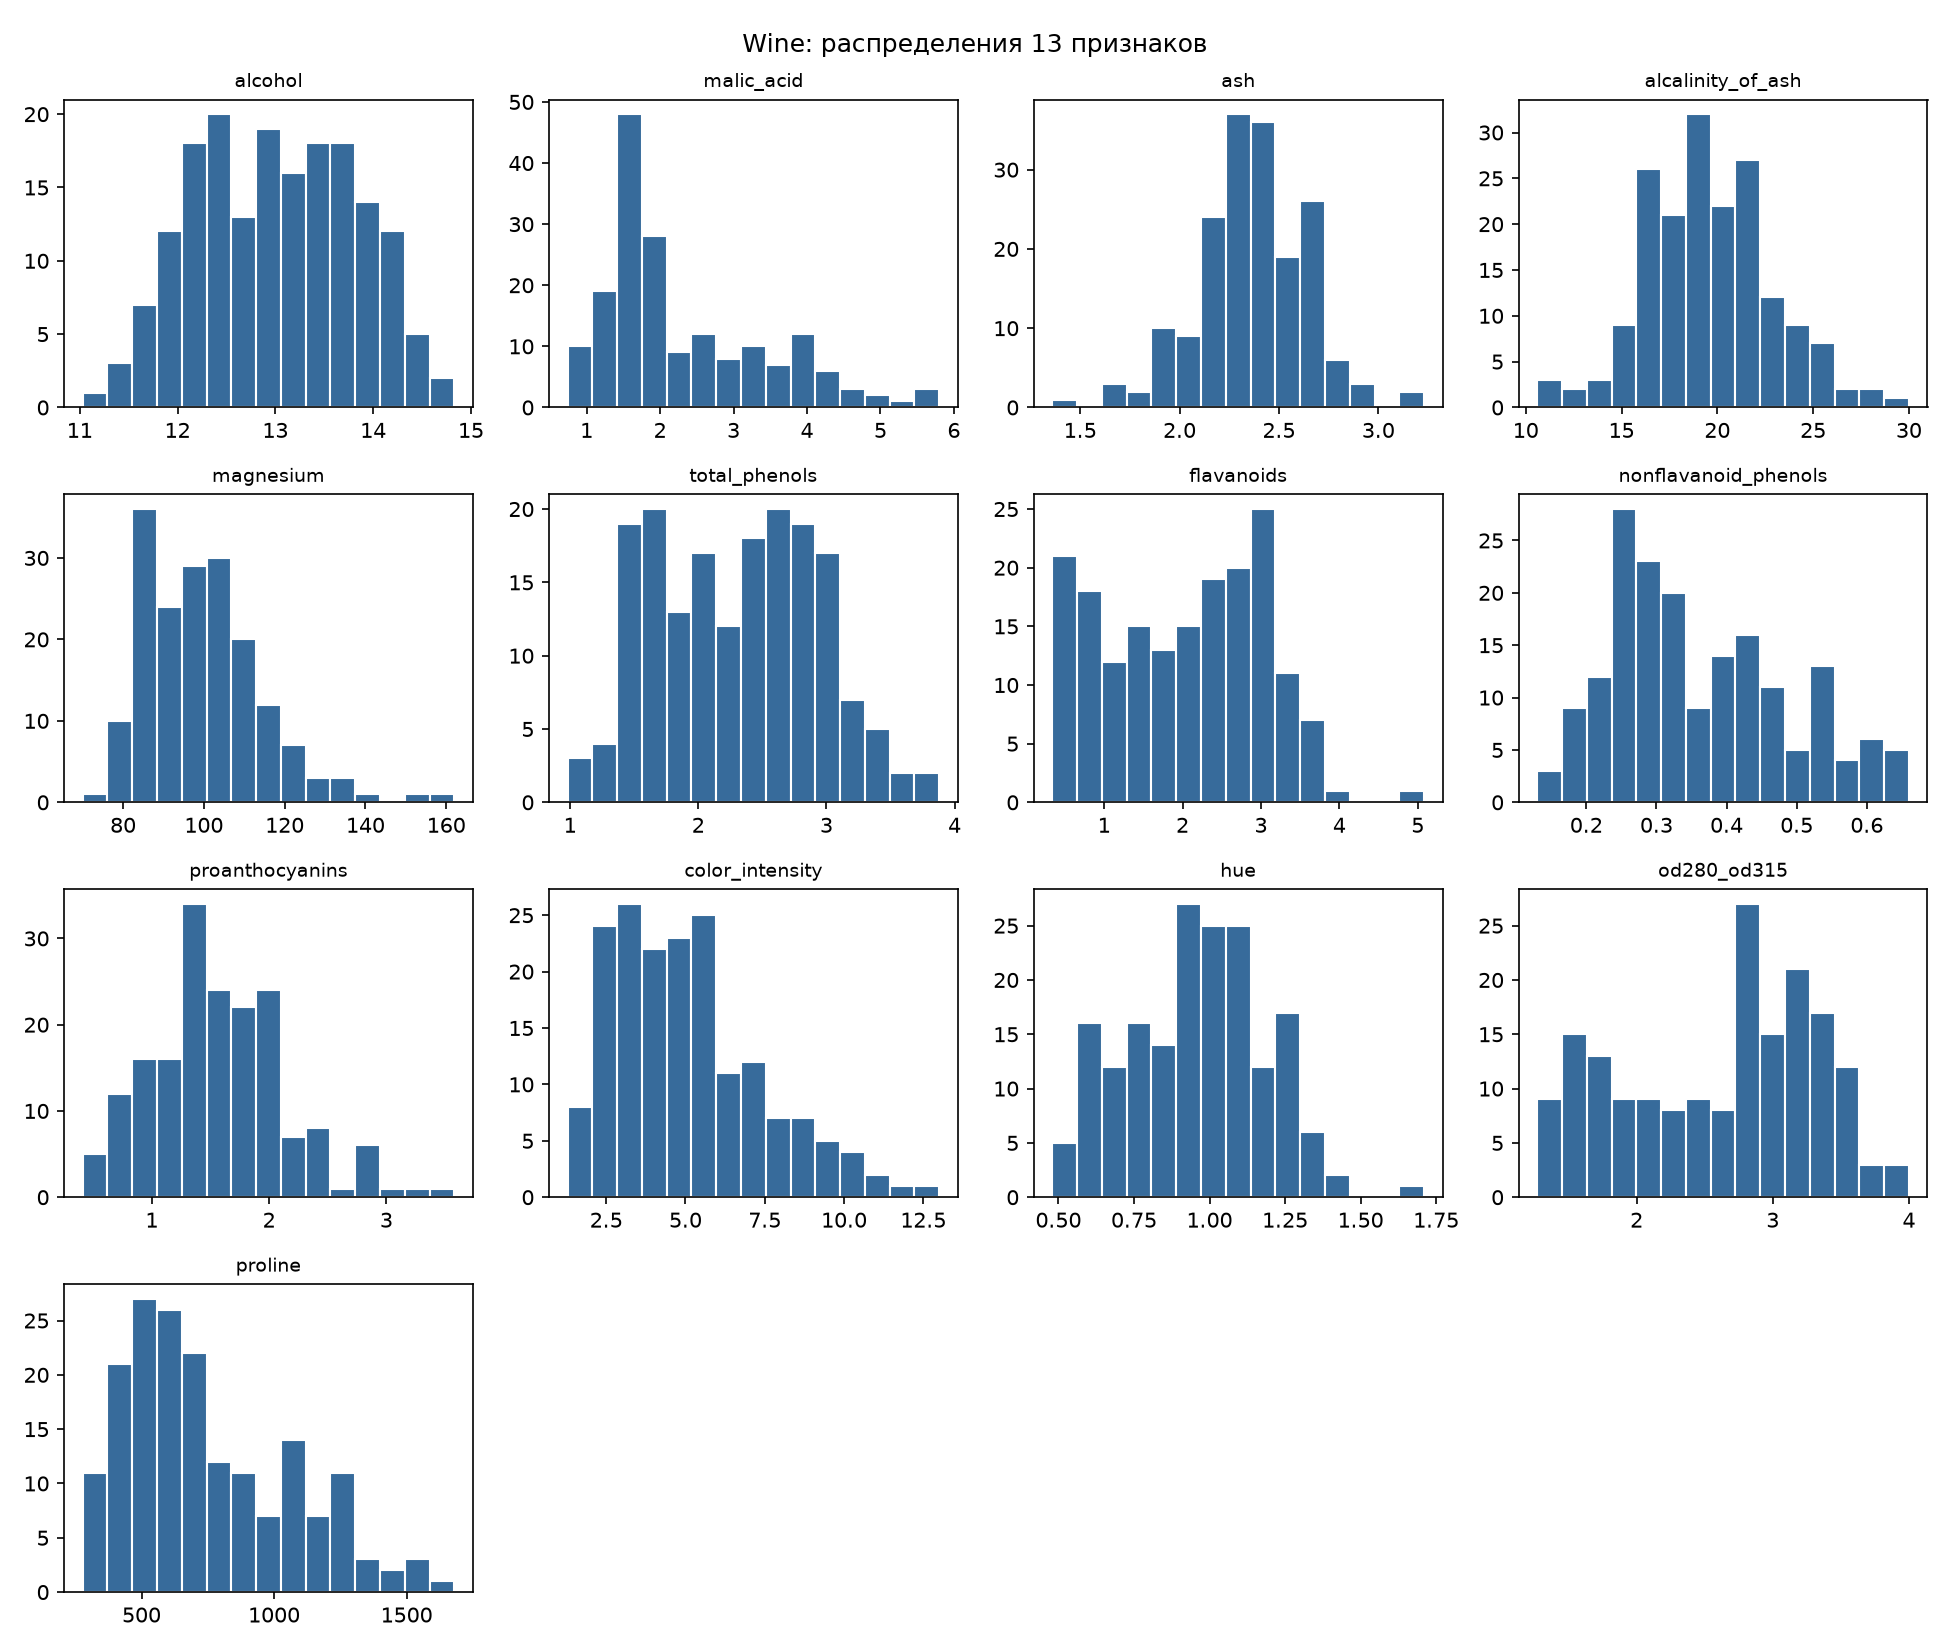

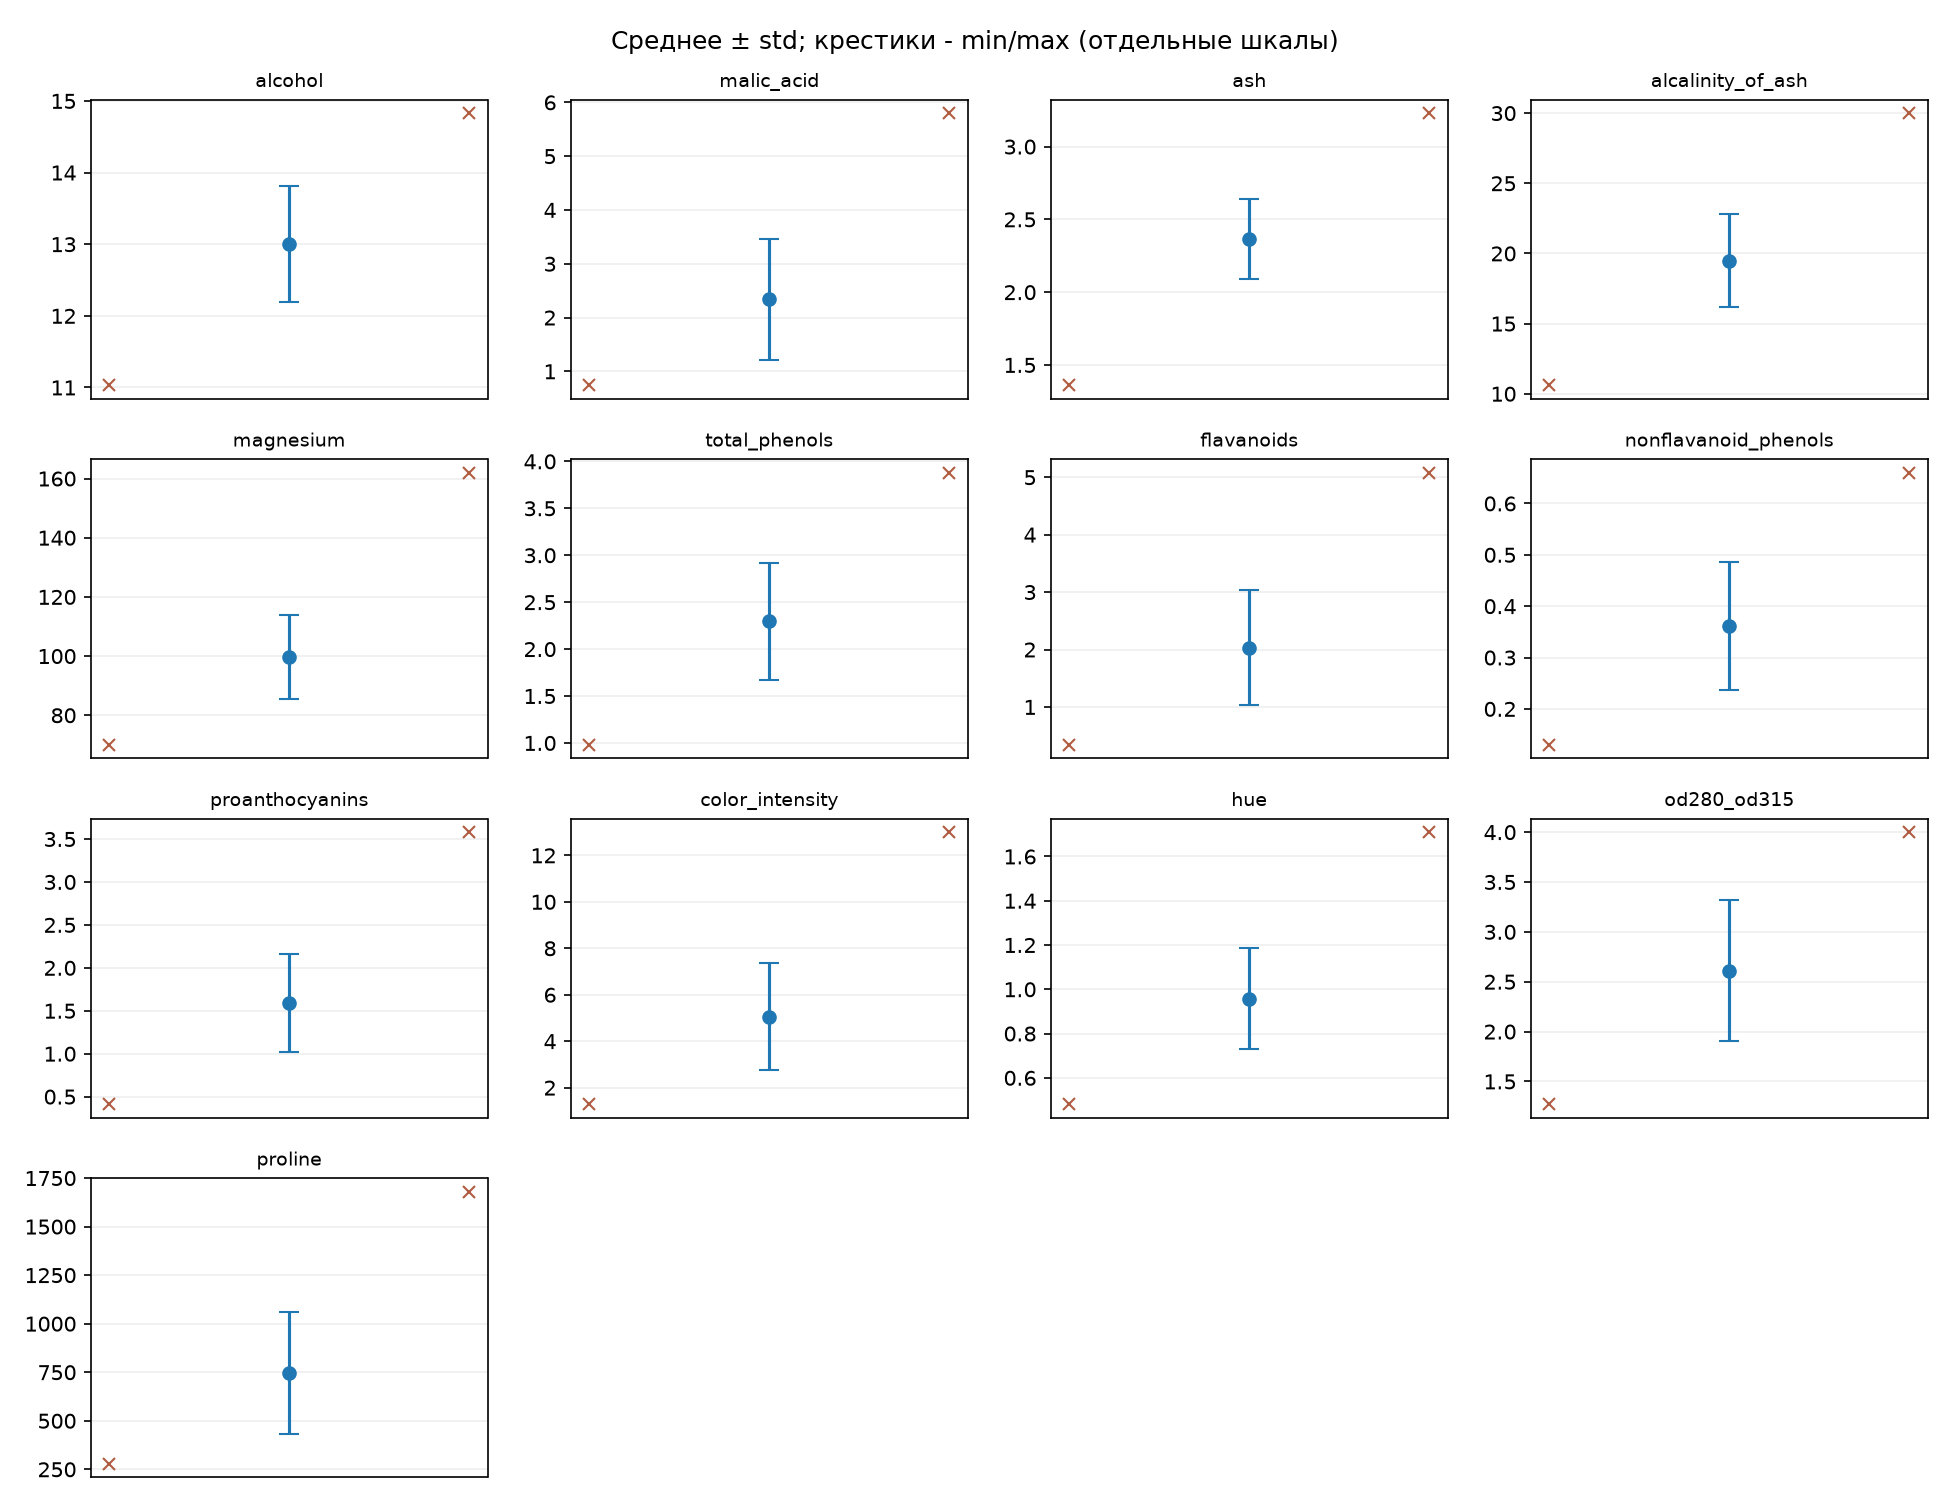

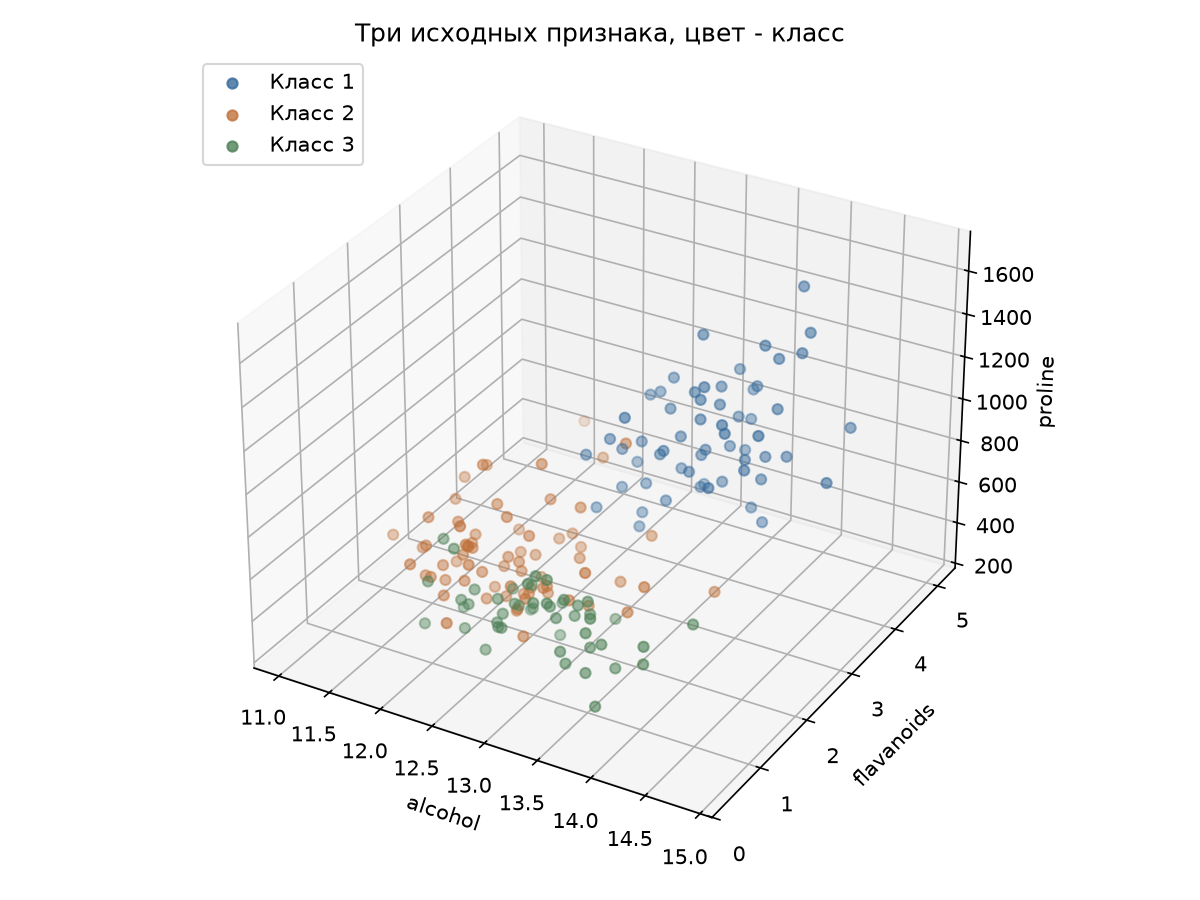

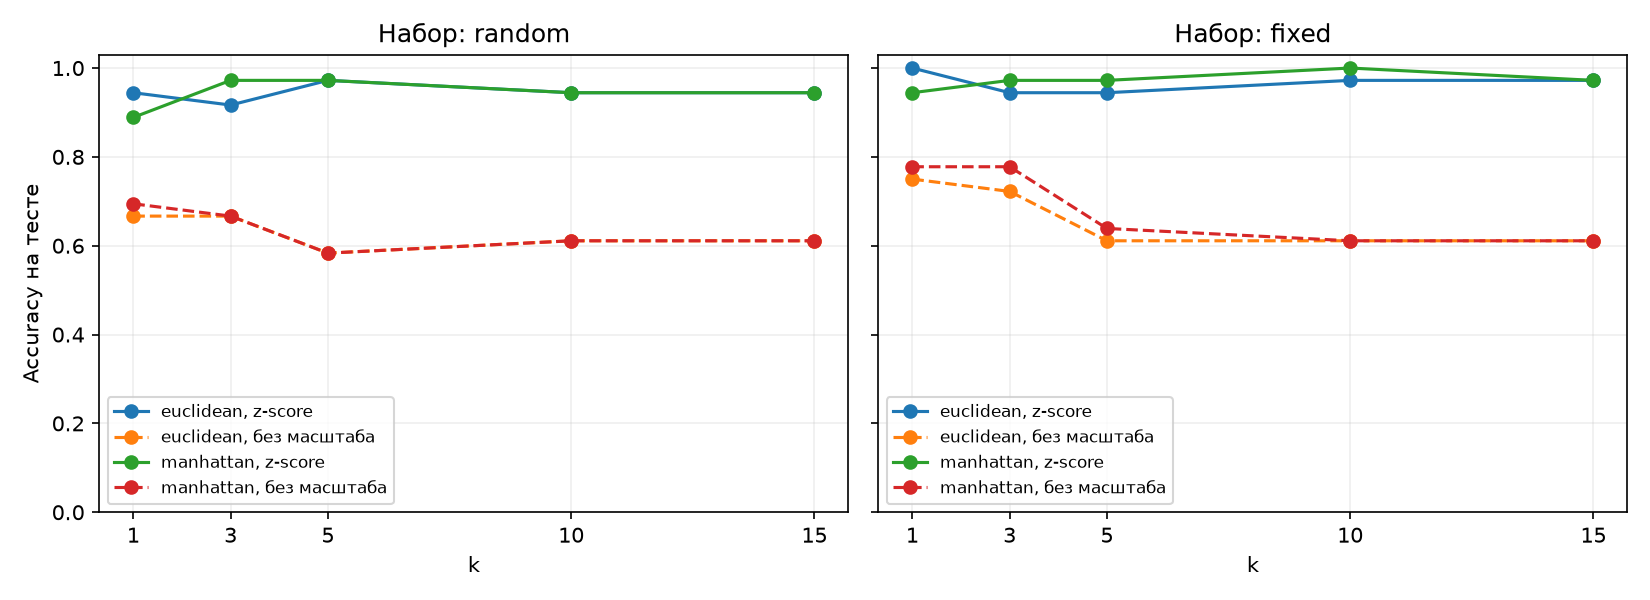

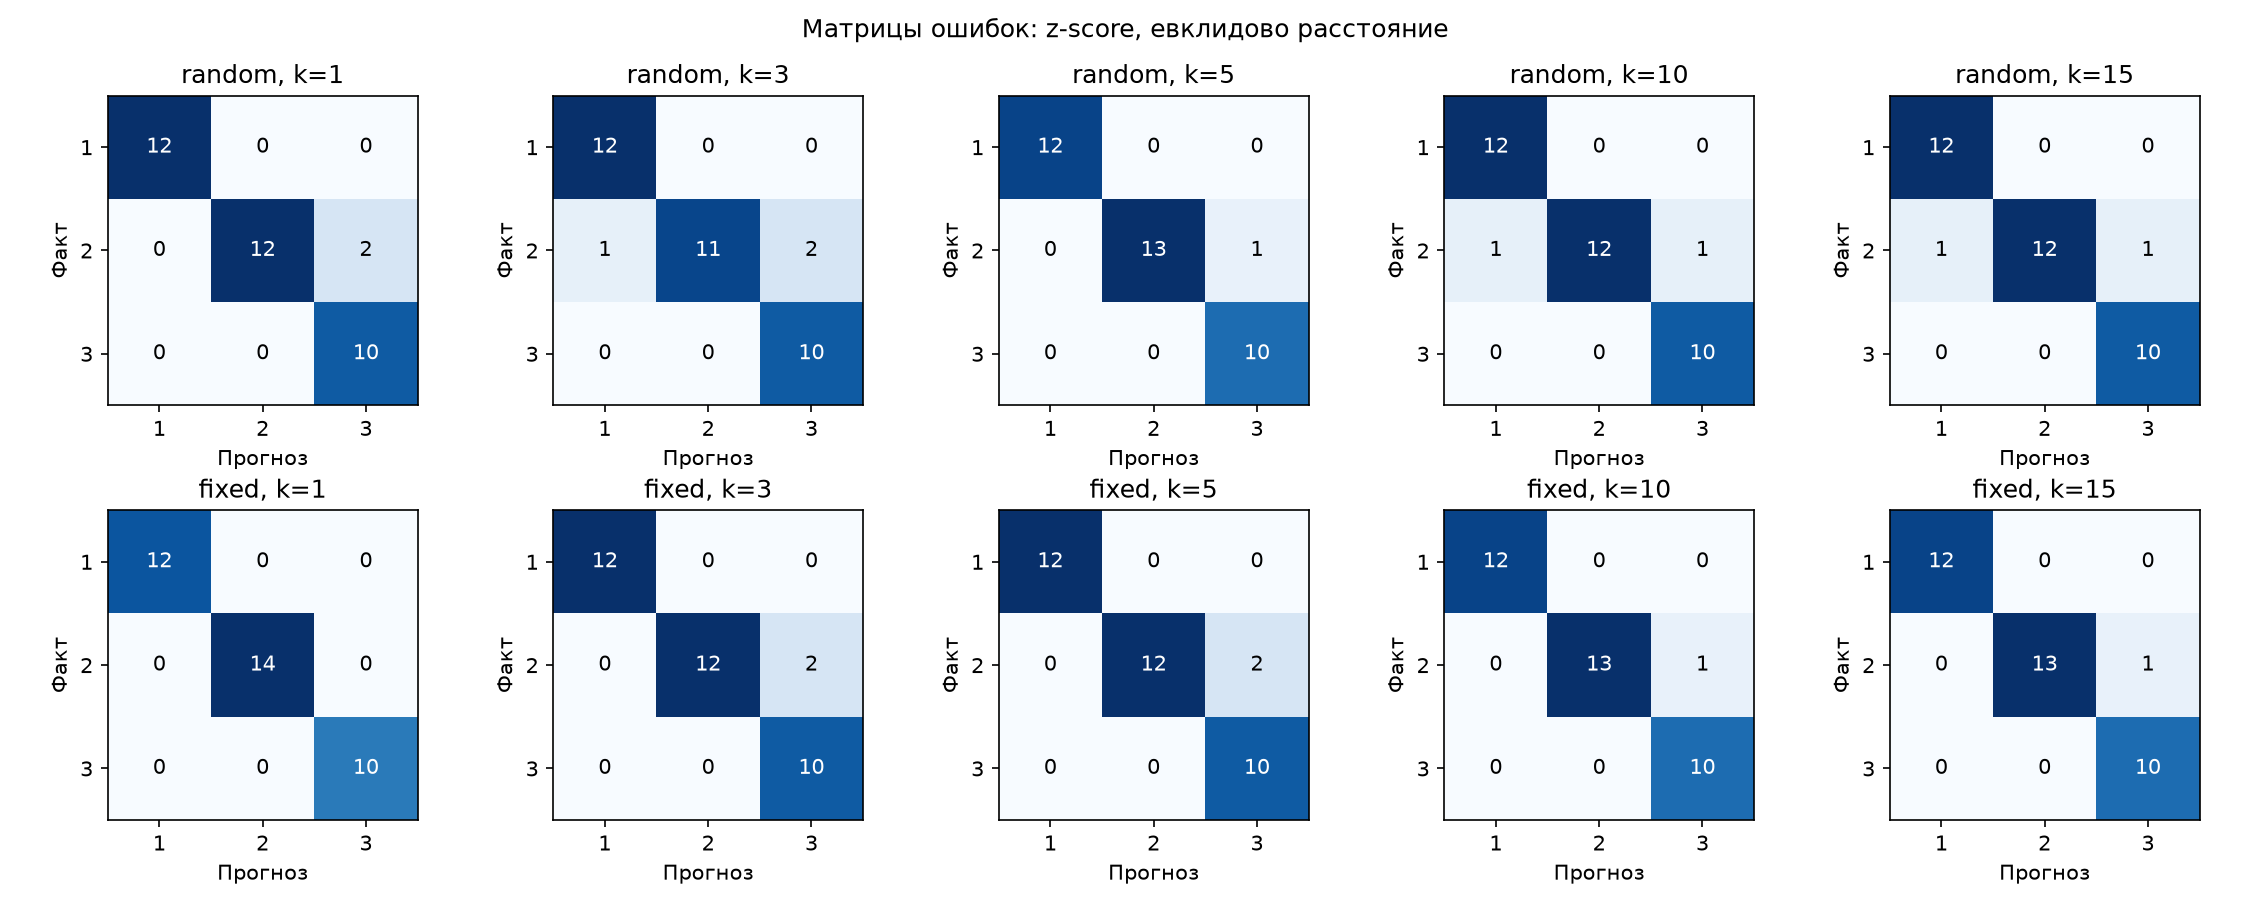

In [3]:
for name in ['01_histograms.png', '02_mean_std.png', '03_features_3d.png', '04_accuracy_k.png', '05_confusion_matrices.png']:
    display(Image(filename=str(ROOT / 'results/figures' / name)))

## Выводы
Стандартизация существенно повлияла на качество k-NN. Для random при k=5 и евклидовом расстоянии Accuracy выросла с 0.5833 до 0.9722. Fixed при k=1 после стандартизации дал 36 правильных ответов из 36. Результат зависит от набора признаков, k и расстояния; 100% на небольшой тестовой выборке не гарантируют такого же качества на новых данных.
